In [ ]:
import xarray as xr
import os
import numpy as np

In [ ]:
files = [f"/work/bg1186/g260200/RUN04b_JUWELS_wpile/outputs_all/out2d_{day}.nc" for day in range(1, 366)]

In [ ]:
variables = ["windSpeedX", "windSpeedY", "elevation", "depthAverageVelX", "depthAverageVelY", "sigWaveHeight", "peakPeriod", "meanWavePeriod", "TM10",
             "meanWaveNumber", "meanWaveLength", "meanWaveDirection", "meanDirSpreading",
             "SCHISM_hgrid_face_nodes", "SCHISM_hgrid_edge_nodes", "dryFlagNode", 
             "SCHISM_hgrid_node_x", "SCHISM_hgrid_node_y", "SCHISM_hgrid_face_x", "SCHISM_hgrid_face_y", "SCHISM_hgrid_edge_x", "SCHISM_hgrid_edge_y",
            ]

In [ ]:
ds = xr.open_mfdataset(files, chunks="auto")

FileNotFoundError: [Errno 2] No such file or directory: '/work/bg1186/g260200/RUN04b_JUWELS_wpile/outputs_all/out2d_1.nc'

In [ ]:
ds

In [ ]:
ds = ds[variables]
for var in variables:
    ds[var] = ds[var].astype("float32")

for coord in ds.coords:
    if coord != "time":
        ds[coord] = ds[coord].astype("float32")

In [ ]:
encoding = {var: {'chunks': (24, 589428)} for var in ds.data_vars}

In [ ]:
%%time
ds.to_zarr("/work/ka1176/shared_data/2025-wwm-emulator-schism/processed_RUN04b_JUWELS_wpile.zarr", mode="w", encoding=encoding)

In [ ]:
zarrds = xr.open_dataset("/work/ka1176/shared_data/2025-wwm-emulator-schism/processed_RUN04b_JUWELS_wpile.zarr")

In [ ]:
for var in variables:
    print(var, ":")
    print("  mean:", zarrds[var].isel(time=slice(0, 24*90)).mean().values)
    print("  std:", zarrds[var].isel(time=slice(0, 24*90)).std().values)

In [ ]:
variables = ["windSpeedX", "windSpeedY", "sigWaveHeight","meanWavePeriod",
            "SCHISM_hgrid_edge_nodes",  
             "SCHISM_hgrid_node_x", "SCHISM_hgrid_node_y", "SCHISM_hgrid_edge_x", "SCHISM_hgrid_edge_y",
            ]

In [ ]:
cicd = zarrds.isel(time=slice(10*24, 15*24), nSCHISM_hgrid_node=slice(None, None, 100000))[variables]
cicd.to_zarr("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/tests/cicd_data/cicd.zarr", mode="w")

In [ ]:
!zip -r cicd.zarr.zip /work/ka1176/caroline/gitlab/wave-wind-model-emulator/tests/cicd_data/cicd.zarr

In [ ]:
cicd

In [ ]:
vals = zarrds.isel(time=slice(None, 24*90))["meanWavePeriod"].values.flatten()

In [ ]:
np.quantile(vals, [0.01, 0.1, 0.5, 0.9, 0.99])

array([0.        , 3.35866857, 5.46546316, 7.19415569, 8.73603535])

In [ ]:
np.sum(vals>7.5)/len(vals)

np.float64(0.06810428610135275)

(array([7.76736020e+07, 4.19340058e+08, 6.89442812e+08, 8.66124670e+07,
        6.72090000e+04, 2.15050000e+04, 6.13100000e+03, 5.72000000e+02,
        7.70000000e+01, 4.70000000e+01]),
 array([ 0. ,  2.5,  5. ,  7.5, 10. , 12.5, 15. , 17.5, 20. , 22.5, 25. ]),
 <BarContainer object of 10 artists>)

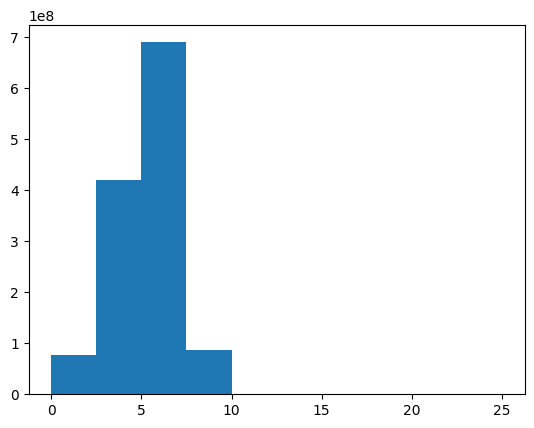

In [ ]:
from matplotlib import pyplot as plt
plt.hist(vals)